<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🔌 MCP：从 server 拉工具、为什么只能 async、每次调用背后的三趟往返

**一句话定位**：MCP 把「工具」变成**跨进程、跨语言的标准接口**；`MultiServerMCPClient.get_tools()` 把 server 的工具转成 LangChain `StructuredTool`，之后和自定义工具一样 `bind_tools`，只是必须 `ainvoke`。
> 对应主课 `3_a_🔥_research_agent_mcp.ipynb`；langchain-mcp-adapters 0.2.2 源码核对。

</div>

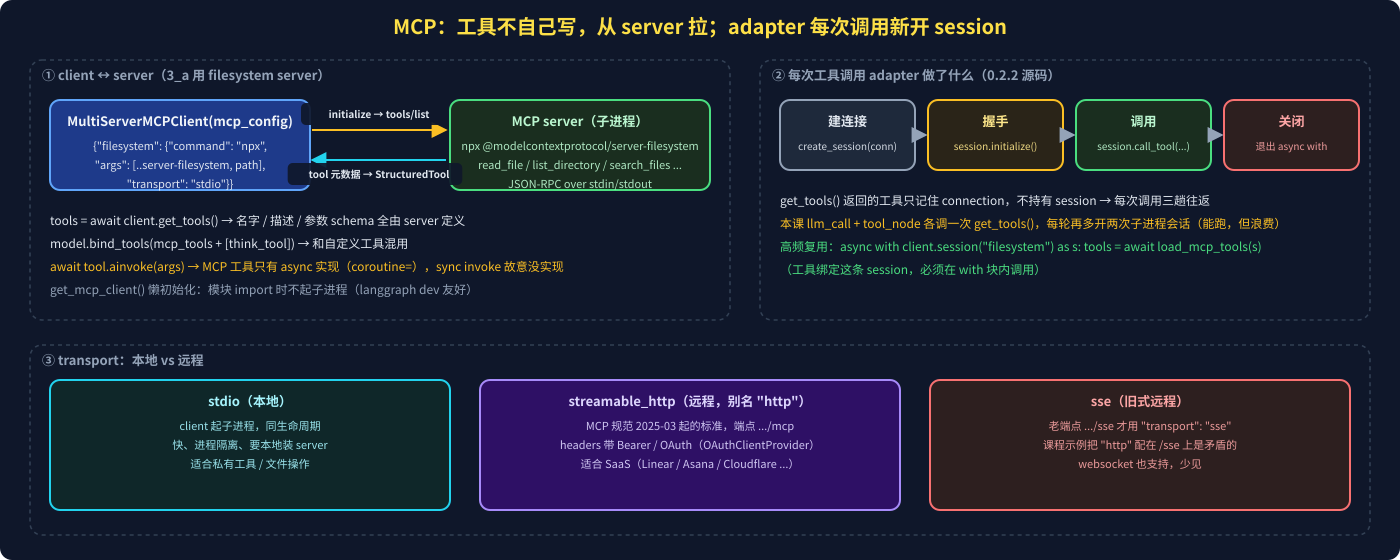

In [ ]:
from IPython.display import SVG
SVG(filename="assets/03_mcp.svg")

### 1️⃣ 最小用法

In [ ]:
from langchain_mcp_adapters.client import MultiServerMCPClient

mcp_config = {
    "filesystem": {                                  # server 别名，随便起
        "command": "npx",
        "args": ["-y", "@modelcontextprotocol/server-filesystem", str(get_current_dir() / "files")],
        "transport": "stdio",                        # 本地子进程
    },
    # "remote": {"url": "https://mcp.example.com/mcp", "transport": "http", "headers": {"Authorization": "Bearer ..."}},
}
_client = None
def get_mcp_client():                                # 懒初始化：import 模块时不起子进程
    global _client
    if _client is None:
        _client = MultiServerMCPClient(mcp_config)
    return _client

async def llm_call(state):
    mcp_tools = await get_mcp_client().get_tools()   # 名字 / 描述 / schema 来自 server
    model_with_tools = model.bind_tools(mcp_tools + [think_tool])
    ...

async def tool_node(state):
    ...
    observation = await tool.ainvoke(args) if name != "think_tool" else tool.invoke(args)   # MCP 工具只有 async

### 2️⃣ 三个「为什么」

| 问题 | 答案 |
|---|---|
| 为什么必须 async | server 是子进程 / 远程服务，通信是 JSON-RPC over pipe / HTTP，延迟不稳定；adapter 把工具包成只有 `coroutine=` 的 `StructuredTool`，sync 调用**故意不实现** |
| 为什么每次调用都「新开 session」 | `get_tools()` 只在启动时开一次 session 做 `tools/list`，返回的工具只记住 `connection`；之后每次 `ainvoke` 都是 **建连接 → `initialize` → `tools/call` → 关闭**。便利换延迟；要复用用 `client.session()` + `load_mcp_tools(session)` |
| 为什么懒初始化 | `langgraph dev` / Deployment 在 import 时扫描模块；模块顶层起子进程会出问题 |

### 3️⃣ transport 速查（0.2.2 实测）

| 值 | 用途 | 备注 |
|---|---|---|
| `stdio` | 本地子进程 | 本课 |
| `streamable_http`（别名 `http` / `streamable-http`） | 远程，MCP 规范 2025-03 起标准 | 端点通常 `/mcp` |
| `sse` | 旧式远程 HTTP+SSE | 端点 `/sse`；课程远程示例应改用它或改 URL |
| `websocket` | 少见 | |

需要登录的远程 server：`mcp` SDK 的 `OAuthClientProvider`（发现 → 浏览器授权拿 code → 换 token），新版 deep agents 课 `m1_(1)/m1.6_gh_auth/` 有手写三步 + SDK 版。

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**🆕 2026-10 对照**

`create_agent(tools=await client.get_tools())` / `create_deep_agent(tools=mcp_tools)` 直接吃同一份列表，接法没变；MCP 也可以反过来当 **server** 写（`FastMCP`，新版课 m5 的 mock 邮箱）。本课文字里「2026 重点：远程 MCP」的判断成立，只是端点形态从 `/sse` 变成了 `/mcp`。

</div>

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**坑**

| 坑 | 结果 |
|---|---|
| 对 MCP 工具用 `invoke` | `NotImplementedError`（只有 async） |
| `"transport": "http"` 配 `/sse` URL | 协议不匹配，连不上 |
| 在 `async with client.session()` 块外调用 `load_mcp_tools(session)` 得到的工具 | session 已关闭，调用失败 |
| 模块顶层 `MultiServerMCPClient(...)` + `get_tools()` | `langgraph dev` import 阶段起子进程 / 事件循环冲突 |
| 工具名拼错（如 ALLOWED 过滤） | 静默空列表，agent「没工具可用」却不报错 |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：MCP = **`MultiServerMCPClient(config).get_tools()` 拉工具 → `bind_tools` → `ainvoke`**；记住两件事 —— **只能 async**，以及 **每次调用都是「连接 + 握手 + 调用」三趟往返**（复用用 `client.session()`）。

</div>